In [2]:
import pandas as pd
import numpy as np
import re
from rdkit import Chem
from rdkit.Chem import PandasTools as pdt
from rdkit.Chem import Draw

from matplotlib import pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics.pairwise import cosine_similarity

In [3]:
# Optimized generation MOO
df = pd.read_csv('../../data/processed/genmol/UKT_f30_qsar-AIH.csv')
df.drop(columns=['Unnamed: 0'], inplace=True)
print(df.shape)
df.head(2)

(1184, 2)


,smiles,score
0,C=C(Cl)C1(C(=O)NCCC(=O)OCC)CC(c2cc(F)cc(F)c2)=NO1,245.72
1,Cc1cc(F)cc(C2=NO[C@@](C)(C(=O)O)C2)c1,221.28


,smiles,score,ROMol,Frag_smiles
0,C=C(Cl)C1(C(=O)NCCC(=O)OCC)CC(c2cc(F)cc(F)c2)=NO1,245.72,,c1ccc(C2=NOCC2)cc1
1,Cc1cc(F)cc(C2=NO[C@@](C)(C(=O)O)C2)c1,221.28,,c1ccc(C2=NOCC2)cc1
2,CCn1cc(CNC(=O)C2(Cl)CC(c3cccc(Cl)c3)=NO2)cn1,220.80,,O=C(NCc1cn[nH]c1)C1CC(c2ccccc2)=NO1
3,CC(COS(C)(=O)=O)NC(=O)C1(C)CC(c2cc(Cl)cc(Cl)c2...,218.03,,c1ccc(C2=NOCC2)cc1
4,CCn1cc(CNC(=O)C2(C)CC(c3cccc(F)c3)=NO2)c(Cl)n1,215.57,,O=C(NCc1cn[nH]c1)C1CC(c2ccccc2)=NO1

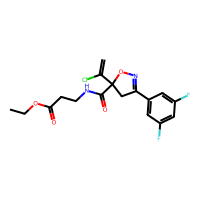
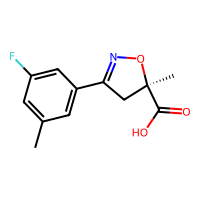
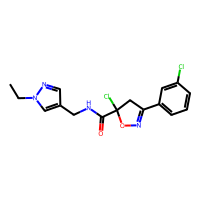
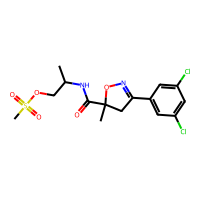
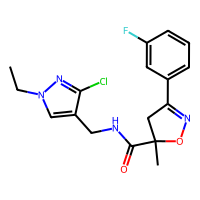

In [4]:
#df = pd.read_csv("./sample_by_prop_from_leads_20250307_c.csv", delimiter="\t")
df_sample = df  #[df["has_isoxazoline_predicted"]==0].iloc[:,[0,1,3]]

pdt.AddMoleculeColumnToFrame(df_sample, smilesCol="smiles", molCol="ROMol")
df_sample.dropna(subset=['ROMol'], inplace=True)

pdt.AddMurckoToFrame(df_sample, molCol='ROMol', MurckoCol='Frag_smiles')
pdt.RenderImagesInAllDataFrames(images=True)

df_sample.head()

#### Helper functions

In [5]:
def flatten(xss):
    return [x for xs in xss for x in xs]

In [6]:
def display_substitution(mol):
    for atom in mol.GetAtoms():
        if atom.GetIsotope() == 1:
            atom.SetProp("_displayLabel", "ring")
        elif atom.GetIsotope() == 2:
            atom.SetProp("_displayLabel", "chain")
        else:
            pass
    return(mol) 

In [7]:
def break_bonds(mol, bonds: tuple) -> list:

    bs = [mol.GetBondBetweenAtoms(x,y).GetIdx() for x,y in bonds]
    b_atm = [mol.GetBondWithIdx(x).GetBeginAtomIdx() for x in bs]
    e_atm = [mol.GetBondWithIdx(x).GetEndAtomIdx() for x in bs]
    bondatoms = list(zip(b_atm, e_atm))
    
    labels_smart = []
    for x, y in bondatoms:
        if mol.GetAtomWithIdx(x).IsInRing() == True:
            l=1
        else:
            l=2
        if mol.GetAtomWithIdx(y).IsInRing() == True:
            r=1
        else:
            r=2
        labels_smart.append((l,r))

    nm = Chem.FragmentOnBonds(mol, bs, dummyLabels=labels_smart)
    rs = Chem.GetMolFrags(nm,asMols=True)
    flist = [Chem.MolToSmiles(f,True) for f in rs]
    
    return(flist)

In [8]:
def get_fragments(smi_list: list, smarts_list: list):
    
    fraglist = []
    mols = [Chem.MolFromSmiles(s) for s in smi_list]
    
    for m in mols:
        if m == None:
            fstr = ""
        else:
            breaks = []
            for smarts in smarts_list:
                brk = m.GetSubstructMatches(Chem.MolFromSmarts(smarts))
                breaks.extend(brk)
            
            breaks_c = [b for b in breaks if b != ()]
            breaks_s = [tuple(sorted(x)) for x in breaks_c]
            breaks_f = list(set(breaks_s))
            if breaks_f == []:
                fstr = Chem.MolToSmiles(m)
            else:
                fstr = break_bonds(m, breaks_f)
                        
        fraglist.append(fstr)
    return(fraglist)

### Overview of bridging fragments connected to at least one ring

'[R]!@[R]'  Ringatome verbunden durch Nicht-Ringbindung = zwischen zwei direkt verbundenen Ringen.  
'[!R][R]'   Bindung zwischen Ringatom und Nicht-Ringatom  
'[N,n][C!RX3]' Spaltung von Amiden  
'[N,O,n,o][C!RX3]' Spaltung von Amiden und Estern

In [9]:
smarts_list = ["[R]!@[R]", "[!R][R]", '[N,n][C!RX3]']
smiles_l = df_sample["smiles"].tolist()
fragments = get_fragments(smi_list=smiles_l, smarts_list=smarts_list)

,smiles,score,ROMol,Frag_smiles,Fragments
0,C=C(Cl)C1(C(=O)NCCC(=O)OCC)CC(c2cc(F)cc(F)c2)=NO1,245.72,,c1ccc(C2=NOCC2)cc1,"[[1*]C(=C)Cl, [1*]C1=NOC([2*])([2*])C1, [1*]C(..."
1,Cc1cc(F)cc(C2=NO[C@@](C)(C(=O)O)C2)c1,221.28,,c1ccc(C2=NOCC2)cc1,"[[1*]C, [1*]c1cc([2*])cc([2*])c1, [1*]F, [1*]C..."
2,CCn1cc(CNC(=O)C2(Cl)CC(c3cccc(Cl)c3)=NO2)cn1,220.80,,O=C(NCc1cn[nH]c1)C1CC(c2ccccc2)=NO1,"[[1*]CC, [2*]c1cnn([2*])c1, [1*]CN[2*], [1*]C(..."
3,CC(COS(C)(=O)=O)NC(=O)C1(C)CC(c2cc(Cl)cc(Cl)c2...,218.03,,c1ccc(C2=NOCC2)cc1,"[[2*]NC(C)COS(C)(=O)=O, [1*]C([2*])=O, [1*]C1=..."
4,CCn1cc(CNC(=O)C2(C)CC(c3cccc(F)c3)=NO2)c(Cl)n1,215.57,,O=C(NCc1cn[nH]c1)C1CC(c2ccccc2)=NO1,"[[1*]CC, [2*]c1cn([2*])nc1[2*], [1*]CN[2*], [1..."

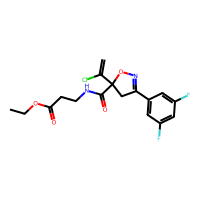
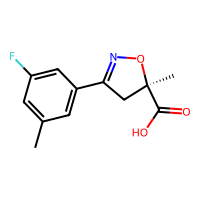
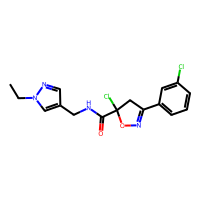
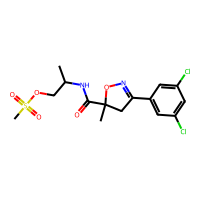
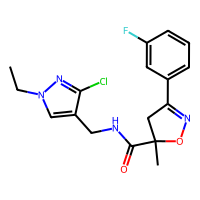

In [10]:
df_sample["Fragments"] = fragments
df_sample.head()

[12:38:12] unsupported number of radical electrons 6




In [11]:
central_fragments = []
for row in fragments:
    central_frags = [f for f in row if len(re.findall(r"[12][*]", f)) > 1 and len(re.findall(r"[1][*]", f)) > 0]
    outer_frags = [f for f in row if len(re.findall(r"[12][*]", f)) == 1]
    central_fragments.append(central_frags)

flat_central_fragments = flatten(central_fragments)

ser = pd.Series(flat_central_fragments)
dct = ser.value_counts().to_dict()

frag_counts = [Chem.MolFromSmiles(x) for x in dct.keys()]
frag_counts_subs = [display_substitution(m) for m in frag_counts]

legend_frags = [f"{k}\nOccurence: {v}" for k, v in dct.items()]

img=Draw.MolsToGridImage(frag_counts_subs,molsPerRow=6,subImgSize=(250,250), legends=legend_frags, maxMols=len(frag_counts_subs))
img

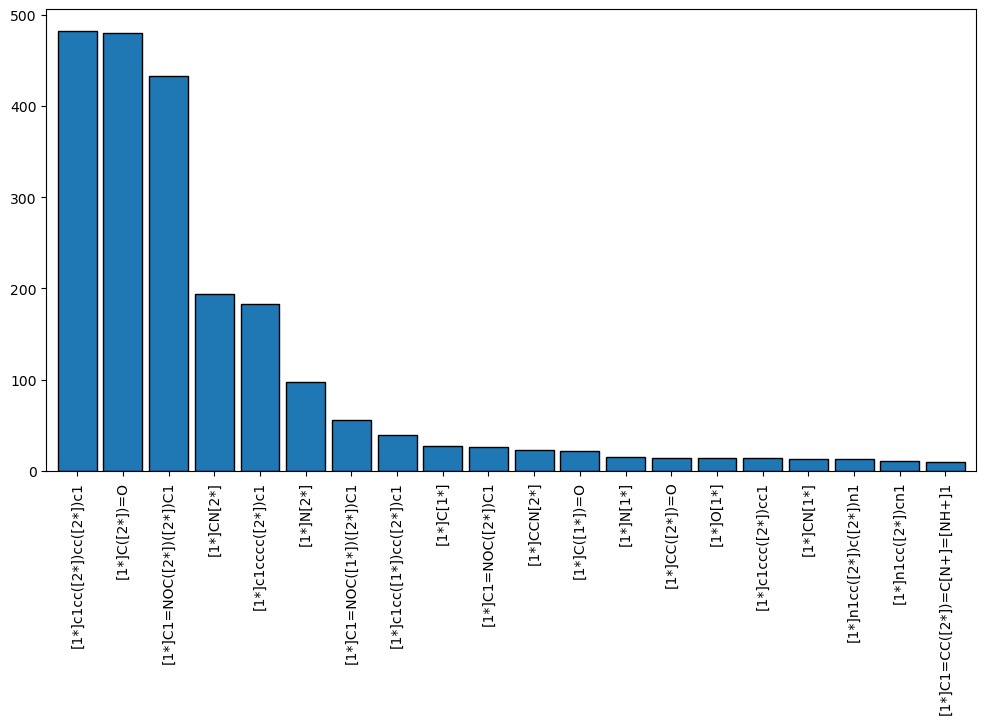

In [12]:
ax = ser.value_counts()[:20].plot(kind='bar', rot=90, width=0.85, ec='k', figsize=(12, 6))

### Example of a display of the cosine similarities of the fragment vectors of sampled molecules with respect to the seed molecule

#### Fragmentation of the sampled molecules. Basis for fragmentation is the full structure, not the Murcko fragments.

,smiles,score,ROMol,Frag_smiles,Fragments
0,C=C(Cl)C1(C(=O)NCCC(=O)OCC)CC(c2cc(F)cc(F)c2)=NO1,245.72,,c1ccc(C2=NOCC2)cc1,"[[1*]C(=C)Cl, [1*]C1=NOC([2*])([2*])C1, [1*]C(..."
1,Cc1cc(F)cc(C2=NO[C@@](C)(C(=O)O)C2)c1,221.28,,c1ccc(C2=NOCC2)cc1,"[[1*]C, [1*]c1cc([2*])cc([2*])c1, [1*]F, [1*]C..."
2,CCn1cc(CNC(=O)C2(Cl)CC(c3cccc(Cl)c3)=NO2)cn1,220.80,,O=C(NCc1cn[nH]c1)C1CC(c2ccccc2)=NO1,"[[1*]CC, [2*]c1cnn([2*])c1, [1*]CN[2*], [1*]C(..."
3,CC(COS(C)(=O)=O)NC(=O)C1(C)CC(c2cc(Cl)cc(Cl)c2...,218.03,,c1ccc(C2=NOCC2)cc1,"[[2*]NC(C)COS(C)(=O)=O, [1*]C([2*])=O, [1*]C1=..."
4,CCn1cc(CNC(=O)C2(C)CC(c3cccc(F)c3)=NO2)c(Cl)n1,215.57,,O=C(NCc1cn[nH]c1)C1CC(c2ccccc2)=NO1,"[[1*]CC, [2*]c1cn([2*])nc1[2*], [1*]CN[2*], [1..."

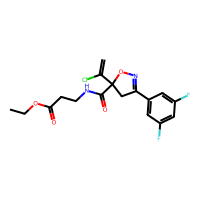
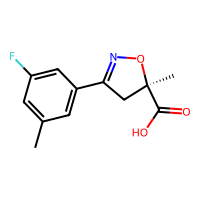
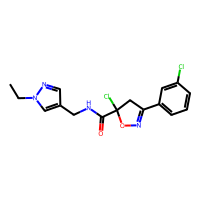
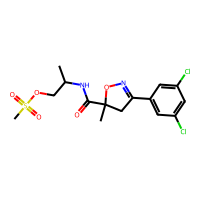
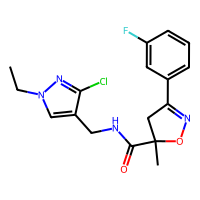

In [13]:
smarts_list = ["[R]!@[R]", "[!R][R]", '[N,n][C!RX3]']
smiles_l = df_sample["smiles"].tolist()
fragments = get_fragments(smi_list=smiles_l, smarts_list=smarts_list)

df_sample["Fragments"] = fragments
df_sample.head()


#### Seed molecules and their fragments are added to the dataframe.

In [14]:
smi_list = ["CC1=NN(CC)C=C1CNC(=O)C1CC(=NO1)C1C=C(Br)C=CC=1", "COC(=O)CCNC(=O)C1(C)CC(=NO1)C1C=C(Cl)C=C(Cl)C=1"]
fr_seed_list = get_fragments(smi_list=smi_list, smarts_list=smarts_list)

df_seeds = pd.DataFrame({"based_on": ["BCS-CE65417", "BCS-CN20332"], "smiles": smi_list, "Fragments": fr_seed_list, "seed": [1,1]})
df_seeds

,based_on,smiles,Fragments,seed
0,BCS-CE65417,CC1=NN(CC)C=C1CNC(=O)C1CC(=NO1)C1C=C(Br)C=CC=1,"[[1*]C, [2*]c1cn([2*])nc1[2*], [1*]CC, [1*]CN[...",1
1,BCS-CN20332,COC(=O)CCNC(=O)C1(C)CC(=NO1)C1C=C(Cl)C=C(Cl)C=1,"[[2*]NCCC(=O)OC, [1*]C([2*])=O, [1*]C1=NOC([2*...",1


In [29]:
df_frags = df_sample[["based_on", "smiles", "Fragments"]]
df_frags.loc[:,"seed"] = 0
df_frags = pd.concat([df_frags, df_seeds], axis=0)
df_frags.info()

<class 'pandas.core.frame.DataFrame'>
Index: 901 entries, 0 to 1
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   based_on   901 non-null    object
 1   smiles     901 non-null    object
 2   Fragments  901 non-null    object
 3   seed       901 non-null    int64 
dtypes: int64(1), object(3)
memory usage: 35.2+ KB


/tmp/ipykernel_25851/858499298.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_frags.loc[:,"seed"] = 0


#### Dataframe is subsetted by seed molecules and the chunks are vectorized individually.

In [30]:
df_frags_417 = df_frags[df_frags["based_on"]=="BCS-CE65417"].reset_index(drop=True)
df_frags_332 = df_frags[df_frags["based_on"]=="BCS-CN20332"].reset_index(drop=True)

In [31]:
vectorizer = CountVectorizer()

df_frags_417_string = df_frags_417["Fragments"].apply(lambda x: " ".join(x))
Y_417 = vectorizer.fit_transform(df_frags_417_string)

df_frags_417_X = df_frags_417[df_frags_417["seed"]==1]
df_frags_417_string_X = df_frags_417_X["Fragments"].apply(lambda x: " ".join(x))
X_417 = vectorizer.transform(df_frags_417_string_X)

print(f"Shape of X: {X_417.shape}")
print(f"Shape of Y: {Y_417.shape}")

Shape of X: (1, 201)
Shape of Y: (447, 201)


In [32]:
vectorizer2 = CountVectorizer()

df_frags_332_string = df_frags_332["Fragments"].apply(lambda x: " ".join(x))
Y_332 = vectorizer2.fit_transform(df_frags_332_string)

df_frags_332_X = df_frags_332[df_frags_332["seed"]==1]
df_frags_332_string_X = df_frags_332_X["Fragments"].apply(lambda x: " ".join(x))
X_332 = vectorizer2.transform(df_frags_332_string_X)

print(f"Shape of X: {X_332.shape}")
print(f"Shape of Y: {Y_332.shape}")

Shape of X: (1, 169)
Shape of Y: (454, 169)


#### Calculation of the cosine similarity of each molecule vector to the seed molecule vector and display as a histogram.

In [33]:
cosine_similarities = cosine_similarity(X_417, Y_417)
df_frags_417["cosine_sim"] = cosine_similarities.reshape(-1)

cosine_similarities2 = cosine_similarity(X_332, Y_332)
df_frags_332["cosine_sim"] = cosine_similarities2.reshape(-1)

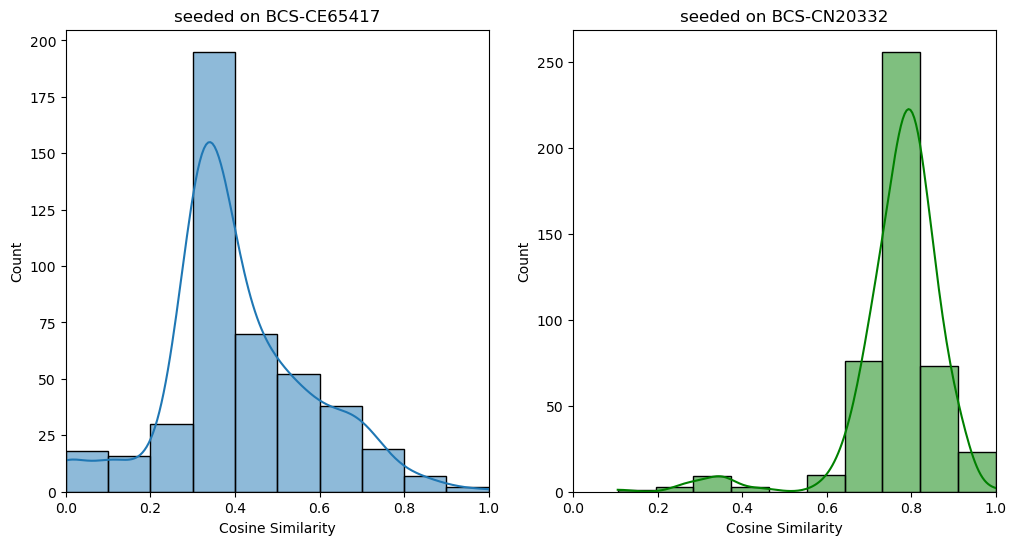

In [34]:
data417 = df_frags_417["cosine_sim"]
data332 = df_frags_332["cosine_sim"]
fig, ax = plt.subplots(figsize=(12, 6), ncols=2)

sns.histplot(data417, bins=10, kde=True, ax=ax[0])
sns.histplot(data332, bins=10, kde=True, ax=ax[1], color="green")
ax[0].set_xlim(0, 1)
ax[1].set_xlim(0, 1)
ax[0].set_title("seeded on BCS-CE65417")
ax[1].set_title("seeded on BCS-CN20332")
ax[0].set_xlabel("Cosine Similarity")
ax[1].set_xlabel("Cosine Similarity")
plt.show()